# M7 · Validation and Final Report (pandas + matplotlib)

**Goal:** prove what the cleaning achieved, measured on the **full** raw and clean data:

1. **Before vs after validity**: for each key column, the share of rows whose value is valid, measured with the same rule on the raw file and on the clean file.
2. **Issue resolution**: every one of the issues logged in M1 with its outcome (fixed, flagged for review, or kept by design).
3. **Integrity checks** across tables (from M6).
4. **Data dictionary** for every clean file.

**Output:** `03_clean_data_and_report/data_cleaning_report.xlsx`, the one file the client reads first (a `guide` sheet explains every delivered file). The charts are also saved as PNG in `output/` in this folder.

## 1. Setup

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

RAW_DIR = Path("../../01_data_and_task/raw_data")
CLEAN_DIR = Path("../../03_clean_data_and_report/clean_data")
DELIVERY_DIR = Path("../../03_clean_data_and_report")
OUT_DIR = Path("output")  # charts of this milestone
OUT_DIR.mkdir(exist_ok=True)
ISSUE_LOG = Path("../01_profiling-pandas/output/issue_log.xlsx")
FIX_LOGS = {
    2: Path("../02_cleaning_customers-pandas/output/m2_fix_log.xlsx"),
    3: Path("../03_cleaning_products-excel_powerquery/output/m3_fix_log.xlsx"),
    4: Path("../04_cleaning_orders-pandas_numpy/output/m4_fix_log.xlsx"),
    5: Path("../05_cleaning_clickstream-pandas/output/m5_fix_log.xlsx"),
    6: Path("../06_cleaning_tickets-sql/output/m6_fix_log.xlsx"),
}
READ_RAW = dict(dtype=str, keep_default_na=False, encoding="utf-8")
CUTOFF = pd.Timestamp("2025-12-03")  # first moment after the data export day

raw = {
    "customers": pd.read_csv(RAW_DIR / "crm_50000_customers_dirty_v3.csv", **READ_RAW),
    "products": pd.read_csv(RAW_DIR / "product_catalog_dirty_30pct.csv", **READ_RAW),
    "orders": pd.read_csv(RAW_DIR / "orders_300k_dirty.csv", **READ_RAW),
    "tickets": pd.read_csv(RAW_DIR / "support_tickets_30000_dirty.csv", **READ_RAW),
}
clean = {
    "customers": pd.read_excel(CLEAN_DIR / "customers_clean.xlsx", sheet_name="customers",
                               dtype={"phone_e164": str, "phone_ext": str, "phone_raw": str}),
    "products": pd.read_excel(CLEAN_DIR / "products_clean.xlsx", sheet_name="products_clean"),
    "orders": pd.read_excel(CLEAN_DIR / "orders_clean.xlsx", sheet_name="orders"),
    "tickets": pd.read_excel(CLEAN_DIR / "tickets_clean.xlsx", sheet_name="tickets"),
    "clickstream": pd.read_excel(CLEAN_DIR / "clickstream_clean.xlsx", sheet_name="clickstream"),
}
for name, df in clean.items():
    print(f"{name:<12} raw {len(raw[name]) if name in raw else 500_000:>8,} rows -> clean {len(df):>8,} rows")

customers    raw   50,000 rows -> clean   48,200 rows
products     raw      500 rows -> clean      500 rows
orders       raw  300,000 rows -> clean  300,000 rows
tickets      raw   30,000 rows -> clean   30,000 rows
clickstream  raw  500,000 rows -> clean  500,000 rows


## 2. Validity rules

One rule per column, applied identically before and after. A row counts as **valid** only if the value is present **and** correct. Blank, placeholder or impossible values count as not valid in both, so values that were set to null in cleaning do **not** inflate the "after" score.

In [2]:
STANDARD_CATEGORIES = {"automotive", "beauty", "clothing", "electronics", "home", "kitchen", "sports", "toys"}
URL_PATTERN = r"https://shop\.example\.com/(|cart|search\?q=[a-z0-9+%]+|category/[a-z]+|product/PROD-\d{4})"


def text(s):
    return s.fillna("").astype(str)


def clean_name(s):
    s = text(s)
    tripled = s.astype(object).str.match(r"(?i)^(.)\1(.)\2(.)\3").astype(bool)
    return s.str.fullmatch(r"[A-Za-z '\-]+") & s.eq(s.str.title()) & ~tripled


def valid_email(s):
    return text(s).str.fullmatch(r"[a-z0-9._%+-]+@[a-z0-9.-]+\.[a-z]{2,}")


def proper_words(s):
    s = text(s)
    return s.str.fullmatch(r"[A-Z][a-z]*( [A-Z][a-z]*)*") & ~s.str.contains("aa")


def positive_number(s, placeholders=()):
    s = text(s)
    num = pd.to_numeric(s, errors="coerce")
    return s.str.fullmatch(r"\d+(\.\d+)?") & num.gt(0) & ~s.isin(placeholders)


def iso_before_cutoff(s, pattern):
    s = text(s)
    ts = pd.to_datetime(s.where(s.str.fullmatch(pattern)), format="ISO8601", errors="coerce", utc=True)
    return ts.notna() & ts.lt(CUTOFF.tz_localize("UTC"))


def in_set(s, allowed):
    return text(s).isin(allowed)


def not_repeated(s, factor=10, normal=None):
    """False for a value that occurs more than factor x the median count (an injected placeholder).
    normal: regex of the values that define a normal count (e.g. plain dates, not unique timestamps)."""
    s = text(s)
    counts = s[s.ne("")].value_counts()
    base = counts if normal is None else counts[counts.index.str.fullmatch(normal)]
    return ~s.isin(counts[counts > factor * base.median()].index)


r, c = raw, clean
RULES = [
    # table, column, rule description, valid-before mask, valid-after mask
    ("customers", "first_name", "letters only, title case, no doubled-letter typo",
     clean_name(r["customers"]["first_name"]), clean_name(c["customers"]["first_name"])),
    ("customers", "last_name", "letters only, title case, no doubled-letter typo",
     clean_name(r["customers"]["last_name"]), clean_name(c["customers"]["last_name"])),
    ("customers", "email", "present and valid format",
     valid_email(r["customers"]["email"]), valid_email(c["customers"]["email"])),
    ("customers", "phone", "E.164 (+1 and a valid 10-digit US number)",
     text(r["customers"]["phone_number"]).str.fullmatch(r"\+1[2-9]\d{2}[2-9]\d{6}"),
     text(c["customers"]["phone_e164"]).str.fullmatch(r"\+1[2-9]\d{2}[2-9]\d{6}")),
    ("customers", "customer_id", "unique (one row per customer)",
     ~r["customers"]["customer_id"].duplicated(keep=False), ~c["customers"]["customer_id"].duplicated(keep=False)),
    ("products", "product_name", "proper case words, no noise, no 'aa' typo",
     proper_words(r["products"]["product_name"]), proper_words(c["products"]["product_name"])),
    ("products", "category", "one of 8 standard categories",
     in_set(r["products"]["category"], STANDARD_CATEGORIES), in_set(c["products"]["category"], STANDARD_CATEGORIES)),
    ("products", "price", "positive number, not a repeated placeholder",
     positive_number(r["products"]["price"]) & not_repeated(r["products"]["price"], 3),
     positive_number(c["products"]["price"].map(lambda v: "" if pd.isna(v) else f"{v:.2f}"))),
    ("orders", "order_amount", "positive number, not a placeholder",
     positive_number(r["orders"]["order_amount"]), c["orders"]["order_amount"].gt(0)),
    ("orders", "order_date", "real ISO date, not a placeholder, not in the future",
     iso_before_cutoff(r["orders"]["order_date"], r"\d{4}-\d{2}-\d{2}")
     & not_repeated(r["orders"]["order_date"], normal=r"\d{4}-\d{2}-\d{2}"),
     c["orders"]["order_date"].notna() & c["orders"]["order_date"].lt(CUTOFF)),
    ("orders", "quantity", "whole number 1-5",
     text(r["orders"]["quantity"]).str.fullmatch(r"[1-5]"), c["orders"]["quantity"].between(1, 5)),
    ("orders", "payment_method", "card / cash / upi / wallet",
     in_set(r["orders"]["payment_method"], {"card", "cash", "upi", "wallet"}),
     in_set(c["orders"]["payment_method"], {"card", "cash", "upi", "wallet"})),
    ("orders", "status", "success / failed / refunded",
     in_set(r["orders"]["status"], {"success", "failed", "refunded"}),
     in_set(c["orders"]["status"], {"success", "failed", "refunded"})),
    ("tickets", "issue_type", "delay / payment / product / refund",
     in_set(r["tickets"]["issue_type"], {"delay", "payment", "product", "refund"}),
     in_set(c["tickets"]["issue_type"], {"delay", "payment", "product", "refund"})),
    ("tickets", "sentiment", "negative / neutral / positive",
     in_set(r["tickets"]["sentiment"], {"negative", "neutral", "positive"}),
     in_set(c["tickets"]["sentiment"], {"negative", "neutral", "positive"})),
    ("tickets", "ticket_created", "real ISO timestamp, not in the future",
     iso_before_cutoff(r["tickets"]["ticket_created"], r"\d{4}-\d{2}-\d{2}T[\d:.]+"),
     c["tickets"]["ticket_created"].notna() & c["tickets"]["ticket_created"].lt(CUTOFF)),
    ("tickets", "ticket_resolved", "real ISO timestamp, not in the future",
     iso_before_cutoff(r["tickets"]["ticket_resolved"], r"\d{4}-\d{2}-\d{2}T[\d:.]+"),
     c["tickets"]["ticket_resolved"].notna() & c["tickets"]["ticket_resolved"].lt(CUTOFF)),
    ("tickets", "support_agent", "letters only, no noise, no 'aa' typo",
     text(r["tickets"]["support_agent"]).str.fullmatch(r"[A-Z][A-Za-z .']*[a-zA-Z.]") & ~text(r["tickets"]["support_agent"]).str.contains("aa"),
     text(c["tickets"]["support_agent"]).str.fullmatch(r"[A-Z][A-Za-z .']*[a-zA-Z.]") & ~text(c["tickets"]["support_agent"]).str.contains("aa")),
]

# clickstream raw is measured in chunks (full file)
click_before = {"page_url": 0, "timestamp": 0, "device_id": 0}
for chunk in pd.read_csv(RAW_DIR / "clickstream_500k_events.csv", chunksize=100_000, **READ_RAW):
    click_before["page_url"] += int(chunk["page_url"].str.fullmatch(URL_PATTERN).sum())
    click_before["timestamp"] += int(iso_before_cutoff(chunk["timestamp"], r"\d{4}-\d{2}-\d{2}T[\d:.]+\+00:00").sum())
    click_before["device_id"] += int(chunk["device_id"].str.fullmatch(r"[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}").sum())
cs = c["clickstream"]
click_after = {
    "page_url": int(text(cs["page_url"]).str.fullmatch(URL_PATTERN).sum()),
    "timestamp": int((cs["timestamp_utc"].notna() & cs["timestamp_utc"].lt(CUTOFF)).sum()),
    "device_id": int(text(cs["device_id"]).str.fullmatch(r"[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}").sum()),
}
CLICK_RULES = {"page_url": "canonical https URL of a known page type",
               "timestamp": "real timestamp in UTC, not in the future",
               "device_id": "lower-case UUID, no spaces, not a placeholder"}

rows = [{"table": t, "column": col, "rule": rule,
         "valid_before_pct": round(before.mean() * 100, 2), "valid_after_pct": round(after.mean() * 100, 2)}
        for t, col, rule, before, after in RULES]
rows += [{"table": "clickstream", "column": col, "rule": CLICK_RULES[col],
          "valid_before_pct": round(click_before[col] / 500_000 * 100, 2),
          "valid_after_pct": round(click_after[col] / 500_000 * 100, 2)} for col in CLICK_RULES]
validity = pd.DataFrame(rows)
validity["change_pts"] = (validity["valid_after_pct"] - validity["valid_before_pct"]).round(2)
assert (validity["change_pts"] >= 0).all(), "cleaning must never make a column less valid"
validity

,table,column,rule,valid_before_pct,valid_after_pct,change_pts
0,customers,first_name,"letters only, title case, no doubled-letter typo",81.25,100.00,18.75
1,customers,last_name,"letters only, title case, no doubled-letter typo",81.27,100.00,18.73
2,customers,email,present and valid format,97.92,97.93,0.01
3,customers,phone,E.164 (+1 and a valid 10-digit US number),0.00,63.94,63.94
4,customers,customer_id,unique (one row per customer),92.93,100.00,7.07
5,products,product_name,"proper case words, no noise, no 'aa' typo",72.80,100.00,27.20
6,products,category,one of 8 standard categories,72.40,94.00,21.60
7,products,price,"positive number, not a repeated placeholder",72.80,79.80,7.00
8,orders,order_amount,"positive number, not a placeholder",74.29,82.82,8.53
9,orders,order_date,"real ISO date, not a placeholder, not in the future",70.00,70.00,0.00


**Why some columns are not at 100% after cleaning:** the remaining rows were set to null on purpose, because the raw value was a placeholder, impossible, or in the future, and no reliable source exists to recover it (for example 30% of order dates). Each of them is listed in the `flagged` sheet of its clean workbook. Inventing a value to reach 100% would make the data look cleaner than it is.

## 3. Issue resolution (every M1 issue)

In [3]:
issue_log = pd.read_excel(ISSUE_LOG, sheet_name="issue_log")
fix_logs = pd.concat(
    [pd.read_excel(path, sheet_name="fix_log").assign(fixed_in=f"M{m}") for m, path in FIX_LOGS.items()],
    ignore_index=True,
)
resolution = issue_log.merge(fix_logs[["issue_id", "rows_fixed", "rows_flagged", "action_taken", "fixed_in"]],
                             on="issue_id", how="left")
assert resolution["action_taken"].notna().all(), resolution.loc[resolution["action_taken"].isna(), "issue_id"].tolist()


def outcome(row):
    if row.rows_fixed > 0 and row.rows_flagged > 0:
        return "fixed + flagged"
    if row.rows_fixed > 0:
        return "fixed"
    if row.rows_flagged > 0:
        return "flagged for review"
    return "kept by design"


resolution["outcome"] = resolution.apply(outcome, axis=1)
print(f"{len(resolution)} issues, all handled: {resolution['action_taken'].notna().all()}")
resolution.groupby(["table", "outcome"]).size().unstack(fill_value=0)

84 issues, all handled: True


outcome,fixed,fixed + flagged,flagged for review,kept by design
table,,,,
clickstream,7,1,3,3
customers,14,0,6,0
orders,7,0,11,3
products,9,0,5,0
tickets,8,1,4,2


In [4]:
resolution.loc[resolution["outcome"].eq("kept by design"), ["issue_id", "table", "column", "issue", "action_taken"]]

,issue_id,table,column,issue,action_taken
41,ISS-042,orders,order_date,full timestamp instead of a date (YYYY-MM-DDTHH:MM:SS.ffffff),"Date part kept (all of these were future dates, see next row)"
44,ISS-045,orders,order_date,blank value,Kept as null (no source to fill)
46,ISS-047,orders,quantity,blank value,Kept as null (no source to fill)
55,ISS-056,clickstream,customer_id,blank customer_id (anonymous visitor),Kept as null; marked is_anonymous (not an error)
58,ISS-059,clickstream,timestamp,blank value,Kept as null (no source to fill)
63,ISS-064,clickstream,page_url,blank value,Kept as null (no source to fill)
73,ISS-074,tickets,resolution_time_hours,resolution_time_hours does not match resolved minus created (more than 1 hou...,"Caused by future timestamps; hours are consistent with every valid pair, so ..."
82,ISS-083,tickets,ticket_resolved,resolved before created,Caused by future timestamps; after cleaning 0 remain


## 4. Summary per table

Flags are counted per record and split by type, so the client sees how much really needs a decision:
- **needs review**: a person should check or decide
- **invalid or missing**: the source value was impossible, a placeholder or blank; it cannot be recovered
- **auto-fixed (info)**: repaired automatically, listed for transparency

A record can have flags of more than one type.

In [5]:
flag_sources = {
    "customers": ("customers_clean.xlsx", "customer_id"),
    "orders": ("orders_clean.xlsx", "order_id"),
    "tickets": ("tickets_clean.xlsx", "ticket_id"),
    "clickstream": ("clickstream_clean.xlsx", "event_id"),
}
FLAG_TYPES = {"needs review": "records_needs_review",
              "invalid or missing value": "records_invalid_or_missing",
              "auto-fixed (info)": "records_auto_fixed_info"}

summary_rows = []
for t in ["customers", "products", "orders", "tickets", "clickstream"]:
    cl = clean[t]
    if t == "products":
        fl = cl.loc[cl["flag_type"].notna(), ["product_id", "flag_type"]].rename(columns={"product_id": "key"})
    else:
        f, key = flag_sources[t]
        fl = pd.read_excel(CLEAN_DIR / f, sheet_name="flagged", usecols=[key, "flag_type"]).rename(columns={key: "key"})
    assert fl["flag_type"].isin(FLAG_TYPES).all(), fl["flag_type"].unique()
    per_type = fl.groupby("flag_type")["key"].nunique()
    res = resolution[resolution["table"] == t]
    v = validity[validity["table"] == t]
    summary_rows.append({
        "table": t,
        "raw_rows": len(raw[t]) if t in raw else 500_000,
        "clean_rows": len(cl),
        "issues_logged": len(res),
        "issues_handled": int(res["action_taken"].notna().sum()),
        **{col: int(per_type.get(ft, 0)) for ft, col in FLAG_TYPES.items()},
        "avg_validity_before_pct": round(v["valid_before_pct"].mean(), 1),
        "avg_validity_after_pct": round(v["valid_after_pct"].mean(), 1),
    })
summary = pd.DataFrame(summary_rows)
summary

,table,raw_rows,clean_rows,issues_logged,issues_handled,records_needs_review,records_invalid_or_missing,records_auto_fixed_info,avg_validity_before_pct,avg_validity_after_pct
0,customers,50000,48200,20,20,4902,17380,0,70.7,92.4
1,products,500,500,14,14,0,112,0,72.7,91.3
2,orders,300000,300000,21,21,12883,129917,0,72.9,87.6
3,tickets,30000,30000,15,15,139,12782,12564,71.0,96.2
4,clickstream,500000,500000,14,14,0,44528,0,88.5,95.1


## 4b. Before vs after examples

Real rows from the data, raw value next to clean value, one for each kind of fix. The raw value is shown in quotes so spaces stay visible.

In [6]:
def obj_match(series, pattern):
    """Regex match on object dtype (pandas 3 strings use RE2, which has no backreferences)."""
    return series.astype(object).str.match(pattern).fillna(False).astype(bool)


def fmt(v):
    if v is None or (not isinstance(v, str) and pd.isna(v)):
        return "(empty, flagged)"
    if isinstance(v, pd.Timestamp):
        return v.strftime("%Y-%m-%d") if v == v.normalize() else v.strftime("%Y-%m-%d %H:%M:%S")
    if isinstance(v, float):
        return f"{int(v):,}" if v.is_integer() else f"{v:,.2f}"
    return str(v)


example_rows = []


def example(table, column, frame, key, raw_col, clean_col, mask, what):
    hit = frame[mask]
    assert len(hit), f"no example found for {table}.{column}: {what}"
    row = hit.iloc[0]
    example_rows.append({"table": table, "column": column, "record_id": row[key],
                         "raw_value": repr(row[raw_col]), "clean_value": fmt(row[clean_col]), "what_happened": what})


cu = raw["customers"].merge(clean["customers"], on="customer_id", suffixes=("_raw", ""))
cu["phone_display"] = cu["phone_e164"].astype(str) + " ext " + cu["phone_ext"].astype(str)
example("customers", "first_name", cu, "customer_id", "first_name_raw", "first_name",
        obj_match(cu["first_name_raw"], r"^([A-Za-z])\1([a-z])\2"), "doubled-letter typo rebuilt")
example("customers", "last_name", cu, "customer_id", "last_name_raw", "last_name",
        cu["last_name_raw"].str.contains(r"\d"), "digit removed")
example("customers", "first_name", cu, "customer_id", "first_name_raw", "first_name",
        cu["first_name_raw"].str.fullmatch(r"[a-z][A-Z]+"), "letter case fixed")
example("customers", "phone_number", cu, "customer_id", "phone_number", "phone_display",
        cu["phone_number"].str.contains("x") & cu["phone_e164"].notna() & cu["phone_number"].str.startswith("("),
        "converted to E.164, extension split off")
example("customers", "phone_number", cu, "customer_id", "phone_number", "phone_e164",
        cu["phone_e164"].isna(), "invalid US area code: not converted, original kept in phone_raw")
example("customers", "address", cu, "customer_id", "address_raw", "address",
        cu["address_raw"].str.isupper(), "all caps converted")

pr = raw["products"].merge(clean["products"][["product_id", "product_name", "category", "price"]],
                           on="product_id", suffixes=("_raw", ""))
example("products", "product_name", pr, "product_id", "product_name_raw", "product_name",
        pr["product_name_raw"].str.contains(r"[a-z][A-Z]"), "joined words split")
example("products", "product_name", pr, "product_id", "product_name_raw", "product_name",
        pr["product_name_raw"].str.contains("aa"), "'aa' typo fixed")
example("products", "product_name", pr, "product_id", "product_name_raw", "product_name",
        pr["product_name_raw"].str.contains(r"[\d!@*]"), "noise character removed")
example("products", "category", pr, "product_id", "category_raw", "category",
        pr["category_raw"].str.contains("3"), "leetspeak mapped to standard category")
example("products", "category", pr, "product_id", "category_raw", "category",
        pr["category_raw"].isin(["clo", "kit", "ele", "hom", "bea"]), "truncated value mapped to standard category")
example("products", "price", pr, "product_id", "price_raw", "price",
        pr["price_raw"].eq("1,200"), "repeated placeholder price removed")

od = raw["orders"].merge(clean["orders"], on="order_id", suffixes=("_raw", ""))
example("orders", "payment_method", od, "order_id", "payment_method_raw", "payment_method",
        od["payment_method_raw"].eq("c@rd"), "typo mapped")
example("orders", "status", od, "order_id", "status_raw", "status", od["status_raw"].eq("REF"), "abbreviation mapped")
example("orders", "quantity", od, "order_id", "quantity_raw", "quantity", od["quantity_raw"].eq("five"), "number word converted")
example("orders", "order_amount", od, "order_id", "order_amount_raw", "order_amount",
        od["order_amount_raw"].ne(od["order_amount_raw"].str.strip()) & od["order_amount"].notna(), "spaces trimmed")
example("orders", "order_amount", od, "order_id", "order_amount_raw", "order_amount",
        od["order_amount_raw"].eq("-50"), "repeated placeholder amount removed")
example("orders", "order_date", od, "order_id", "order_date_raw", "order_date",
        od["order_date_raw"].eq("31-12-2023"), "placeholder date on 18,050 orders removed")
example("orders", "order_date", od, "order_id", "order_date_raw", "order_date",
        od["order_date_raw"].eq("2024/31/01"), "impossible date (month 31) removed")

tk = raw["tickets"].merge(clean["tickets"], on="ticket_id", suffixes=("_raw", ""))
example("tickets", "issue_type", tk, "ticket_id", "issue_type_raw", "issue_type",
        tk["issue_type_raw"].eq("tnemyap"), "reversed text mapped (SQL REVERSE)")
example("tickets", "issue_type", tk, "ticket_id", "issue_type_raw", "issue_type",
        tk["issue_type_raw"].eq("r3fund"), "leetspeak mapped")
example("tickets", "sentiment", tk, "ticket_id", "sentiment_raw", "sentiment",
        tk["sentiment_raw"].eq("n3gativ3"), "leetspeak mapped")
example("tickets", "support_agent", tk, "ticket_id", "support_agent_raw", "support_agent",
        tk["support_agent_raw"].str.contains("aa") & tk["support_agent_raw"].ne(tk["support_agent"]),
        "typo fixed from the clean spelling of the same agent")
example("tickets", "support_agent", tk, "ticket_id", "support_agent_raw", "support_agent",
        tk["support_agent_raw"].str.endswith("--"), "noise removed")
example("tickets", "ticket_created", tk, "ticket_id", "ticket_created_raw", "ticket_created",
        tk["ticket_created_raw"].eq("2025-12-12T28:77:10") & tk["created_is_derived"],
        "impossible timestamp rebuilt from resolved time minus resolution hours")

cs_raw = pd.read_csv(RAW_DIR / "clickstream_500k_events.csv", nrows=100_000, **READ_RAW)
cs = cs_raw.merge(clean["clickstream"], on="event_id", suffixes=("_raw", ""))
example("clickstream", "page_url", cs, "event_id", "page_url_raw", "page_url",
        cs["page_url_raw"].str.startswith("http://///"), "broken scheme and slashes fixed")
example("clickstream", "page_url", cs, "event_id", "page_url_raw", "page_url",
        cs["page_url_raw"].str.startswith("HTTPS://SHOP.EXAMPLE.COM/PRODUCT"), "lower case, product ID kept")
example("clickstream", "page_url", cs, "event_id", "page_url_raw", "page_url",
        cs["page_url_raw"].str.contains("/prod/"), "wrong path rewritten")
example("clickstream", "timestamp", cs, "event_id", "timestamp", "timestamp_utc",
        cs["timestamp"].str.contains(r"^\d{4}-\d{2}-\d{2} ", regex=True), "space format parsed to UTC")
example("clickstream", "timestamp", cs, "event_id", "timestamp", "timestamp_utc",
        cs["timestamp"].eq("2024/31/01 25:61:00"), "impossible timestamp removed")
example("clickstream", "device_id", cs, "event_id", "device_id_raw", "device_id",
        cs["device_id_raw"].str.fullmatch(r"[0-9a-fA-F]{32}"), "dashes restored to the standard UUID form")
example("clickstream", "device_id", cs, "event_id", "device_id_raw", "device_id",
        cs["device_id_raw"].str.startswith("invalid-device-"), "placeholder device removed")

examples = pd.DataFrame(example_rows)
examples

,table,column,record_id,raw_value,clean_value,what_happened
0,customers,first_name,66c5800b-ad5c-4fac-86df-16472d82f02d,'KKeevvin',Kevin,doubled-letter typo rebuilt
1,customers,last_name,3d12e6c6-cad4-4b98-b3b5-3ebf02623777,'Ha0rt',Hart,digit removed
2,customers,first_name,0d244537-8164-4b84-bcf2-0e43766f3221,'mARIA',Maria,letter case fixed
3,customers,phone_number,e3eca3cc-9010-498a-b9b5-f24afff9ed64,'(589)341-8236x24713',+15893418236 ext 24713,"converted to E.164, extension split off"
4,customers,phone_number,9a3ae2d2-97d7-43b4-843c-ebac2fc0131c,'001-063-045-0948x4636',"(empty, flagged)","invalid US area code: not converted, original kept in phone_raw"
5,customers,address,4375cc64-a523-46b9-a87b-a34e5be6c014,'52798 CALEB MEADOW APT. 352',52798 Caleb Meadow Apt. 352,all caps converted
6,products,product_name,PROD-0016,'StartWear',Start Wear,joined words split
7,products,product_name,PROD-0001,'Open Beaautiful',Open Beautiful,'aa' typo fixed
8,products,product_name,PROD-0023,'Magazine Health6',Magazine Health,noise character removed
9,products,category,PROD-0003,'3l3ctronics',electronics,leetspeak mapped to standard category


## 5. Integrity checks (from M6)

In [7]:
integrity = pd.read_excel(FIX_LOGS[6], sheet_name="integrity_checks")
integrity[["check_no", "check_type", "check_name", "failing_rows", "total_rows", "status"]]

,check_no,check_type,check_name,failing_rows,total_rows,status
0,1,primary key,customers.customer_id is unique,0,48200,pass
1,2,primary key,products.product_id is unique,0,500,pass
2,3,primary key,orders.order_id is unique,0,300000,pass
3,4,primary key,tickets.ticket_id is unique,0,30000,pass
4,5,primary key,clickstream.event_id is unique,0,500000,pass
5,6,foreign key,orders.customer_id exists in customers,0,300000,pass
6,7,foreign key,orders.product_id exists in products,0,300000,pass
7,8,foreign key,tickets.customer_id exists in customers,0,30000,pass
8,9,foreign key,clickstream.customer_id exists in customers (anonymous events excluded),0,349447,pass
9,10,foreign key,clickstream.product_id exists in products,0,368942,pass


## 6. Charts

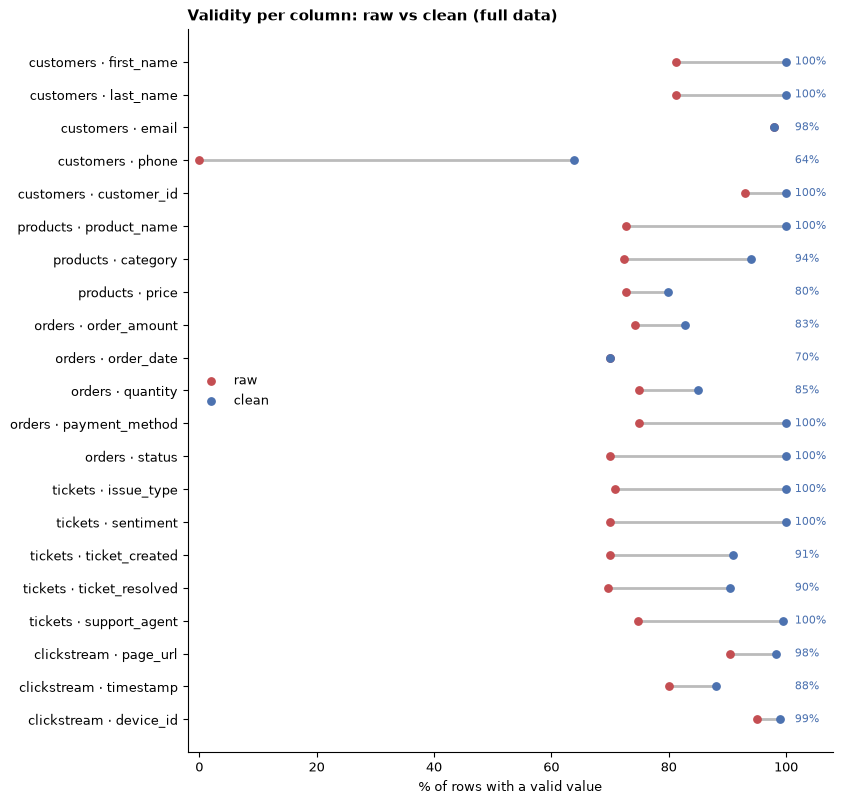

In [8]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
BEFORE, AFTER = "#C44E52", "#4C72B0"

v = validity.iloc[::-1].reset_index(drop=True)
labels = v["table"] + " · " + v["column"]
fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(v) + 1.4))
for y, row in v.iterrows():
    ax.plot([row.valid_before_pct, row.valid_after_pct], [y, y], color="#BBBBBB", linewidth=2, zorder=1)
ax.scatter(v["valid_before_pct"], range(len(v)), color=BEFORE, label="raw", zorder=2, s=28)
ax.scatter(v["valid_after_pct"], range(len(v)), color=AFTER, label="clean", zorder=3, s=28)
for y, row in v.iterrows():
    ax.text(101.5, y, f"{row.valid_after_pct:.0f}%", va="center", fontsize=8, color=AFTER)
ax.set_yticks(range(len(v)), labels)
ax.set_xlim(-2, 108)
ax.set_xlabel("% of rows with a valid value")
ax.set_title("Validity per column: raw vs clean (full data)", loc="left", fontweight="bold")
ax.legend(loc="center left", frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "m7_validity_before_after.png", dpi=150)
plt.show()

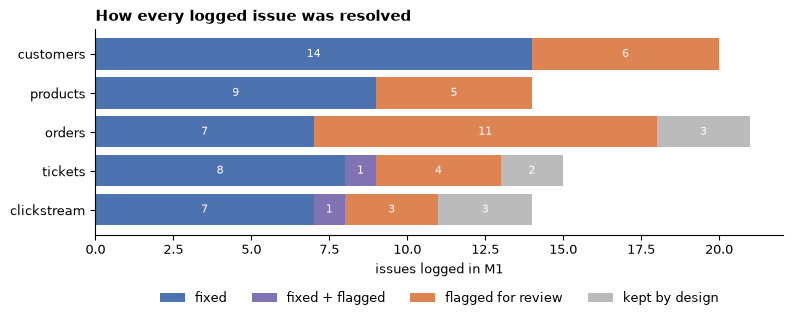

In [9]:
order = ["fixed", "fixed + flagged", "flagged for review", "kept by design"]
colors = {"fixed": "#4C72B0", "fixed + flagged": "#8172B3", "flagged for review": "#DD8452", "kept by design": "#BBBBBB"}
counts = (resolution.groupby(["table", "outcome"]).size().unstack(fill_value=0)
          .reindex(columns=order, fill_value=0).reindex(["customers", "products", "orders", "tickets", "clickstream"]))
fig, ax = plt.subplots(figsize=(8, 3.4))
left = np.zeros(len(counts))
for col in order:
    ax.barh(counts.index, counts[col], left=left, color=colors[col], label=col)
    for y, (l, w) in enumerate(zip(left, counts[col])):
        if w:
            ax.text(l + w / 2, y, str(w), ha="center", va="center", fontsize=8, color="white")
    left += counts[col].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("issues logged in M1")
ax.set_title("How every logged issue was resolved", loc="left", fontweight="bold")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.tight_layout()
fig.savefig(OUT_DIR / "m7_issue_outcomes.png", dpi=150)
plt.show()

## 7. Data dictionary

In [10]:
DESCRIPTIONS = {
    ("customers", "customer_id"): "Customer key (UUID); one golden record per customer",
    ("customers", "first_name"): "First name: noise removed, doubled-letter typo fixed, title case",
    ("customers", "last_name"): "Last name: noise removed, doubled-letter typo fixed, title case",
    ("customers", "email"): "Lower-case email; null when blank in the source",
    ("customers", "email_is_shared"): "True for generic shared####@ inboxes (not personal, never used for matching)",
    ("customers", "phone_e164"): "Phone in E.164 (+1XXXXXXXXXX); null when the number is not a valid US number",
    ("customers", "phone_ext"): "Phone extension split from the number",
    ("customers", "phone_raw"): "Phone exactly as in the source (kept for audit)",
    ("customers", "gender"): "M / F / O as in the source",
    ("customers", "dob"): "Date of birth",
    ("customers", "signup_date"): "Signup date",
    ("customers", "address"): "Street address; all-caps values converted to capitalised words",
    ("customers", "city"): "City as in the source",
    ("customers", "state"): "US state as in the source",
    ("customers", "country"): "Country as in the source (contradicts state in 99.6% of rows)",
    ("customers", "state_country_conflict"): "True when a US state is combined with a non-US country",
    ("customers", "device_count"): "Number of devices; the IDs are in sheet customer_devices",
    ("customers", "source"): "Acquisition channel: app / web / referral",
    ("customers", "needs_review"): "True when at least one flag needs a person's decision",
    ("customers", "dq_flags"): "Every flag reason for this customer (empty = none)",
    ("customer_devices", "customer_id"): "Customer key",
    ("customer_devices", "device_id"): "One device of the customer",
    ("products", "product_id"): "Product key (PROD-####)",
    ("products", "product_name"): "Clean product name (Power Query)",
    ("products", "category_key"): "Helper: normalised raw category used for the lookup",
    ("products", "price_raw"): "Helper: raw price text (trimmed)",
    ("products", "price_number"): "Helper: raw price converted to a number",
    ("products", "category"): "Standard category (XLOOKUP on tbl_category_map); empty when missing in the source",
    ("products", "price_status"): "ok or the reason the price is invalid",
    ("products", "price"): "Clean price; empty when invalid",
    ("products", "review_reason"): "Every problem found in this product (empty = none)",
    ("products", "flag_type"): "invalid or missing value / needs review (empty = no problem)",
    ("orders", "order_id"): "Order key (UUID)",
    ("orders", "customer_id"): "Customer key (all exist in customers)",
    ("orders", "product_id"): "Product key (all exist in products)",
    ("orders", "order_date"): "Order date; null when blank, impossible, placeholder or in the future",
    ("orders", "order_amount"): "Order amount; null when the source held a placeholder (0, -50, 1,200, NaN)",
    ("orders", "is_amount_outlier"): "True when the amount is above the IQR upper fence (kept, needs review)",
    ("orders", "quantity"): "Whole number 1-5; null when blank, zero or negative",
    ("orders", "payment_method"): "card / cash / upi / wallet",
    ("orders", "status"): "success / failed / refunded",
    ("orders", "needs_review"): "True when at least one flag needs a person's decision (e.g. amount outlier)",
    ("orders", "dq_flags"): "Every flag reason for this order (empty = none)",
    ("tickets", "ticket_id"): "Ticket key (UUID)",
    ("tickets", "customer_id"): "Customer key (all exist in customers)",
    ("tickets", "issue_type"): "delay / payment / product / refund",
    ("tickets", "ticket_created"): "Created timestamp; may be rebuilt from resolved - hours (see created_is_derived)",
    ("tickets", "ticket_resolved"): "Resolved timestamp; may be rebuilt from created + hours (see resolved_is_derived)",
    ("tickets", "resolution_time_hours"): "Hours from created to resolved (as in the source; verified consistent)",
    ("tickets", "sentiment"): "negative / neutral / positive",
    ("tickets", "support_agent"): "Agent name: noise removed, typo fixed where a clean spelling exists",
    ("tickets", "created_is_derived"): "True when ticket_created was rebuilt from the other timestamp",
    ("tickets", "resolved_is_derived"): "True when ticket_resolved was rebuilt from the other timestamp",
    ("tickets", "needs_review"): "True when at least one flag needs a person's decision",
    ("tickets", "dq_flags"): "Every flag reason for this ticket (empty = none)",
    ("clickstream", "event_id"): "Event key (UUID)",
    ("clickstream", "session_id"): "Web session (UUID)",
    ("clickstream", "customer_id"): "Customer key; null for anonymous visitors",
    ("clickstream", "is_anonymous"): "True when the event has no customer",
    ("clickstream", "event_type"): "page_view / search / add_to_cart / login",
    ("clickstream", "page_url"): "Canonical URL (https, lower case, no extra slashes); null when blank in the source",
    ("clickstream", "product_id"): "Product key taken from a product URL",
    ("clickstream", "device_id"): "Device as lower-case UUID; null when the source held a placeholder ('invalid-device-N')",
    ("clickstream", "timestamp_utc"): "Event time in UTC (Excel stores milliseconds); null when blank, impossible or in the future",
    ("clickstream", "timestamp_tz_assumed"): "True when the source had no timezone and UTC was assumed",
    ("clickstream", "ingest_run_id"): "Load batch ID (one value for the whole file)",
}

files = {
    "customers": ("customers_clean.xlsx", "customers", clean["customers"]),
    "customer_devices": ("customers_clean.xlsx", "customer_devices",
                         pd.read_excel(CLEAN_DIR / "customers_clean.xlsx", sheet_name="customer_devices")),
    "products": ("products_clean.xlsx", "products_clean", clean["products"]),
    "orders": ("orders_clean.xlsx", "orders", clean["orders"]),
    "tickets": ("tickets_clean.xlsx", "tickets", clean["tickets"]),
    "clickstream": ("clickstream_clean.xlsx", "clickstream", clean["clickstream"]),
}
dict_rows = []
for table, (file, sheet, df) in files.items():
    for col in df.columns:
        filled = df[col].notna() & df[col].astype(str).ne("")
        example = df.loc[filled, col].iloc[0] if filled.any() else ""
        dict_rows.append({
            "file": file, "sheet": sheet, "column": col,
            "type": str(df[col].dtype).replace("object", "text").replace("str", "text"),
            "filled_pct": round(filled.mean() * 100, 2),
            "example": str(example)[:60],
            "description": DESCRIPTIONS[(table, col)],
        })
data_dictionary = pd.DataFrame(dict_rows)
data_dictionary

,file,sheet,column,type,filled_pct,example,description
0,customers_clean.xlsx,customers,customer_id,text,100.00,0d244537-8164-4b84-bcf2-0e43766f3221,Customer key (UUID); one golden record per customer
1,customers_clean.xlsx,customers,first_name,text,100.00,Maria,"First name: noise removed, doubled-letter typo fixed, title case"
2,customers_clean.xlsx,customers,last_name,text,100.00,Day,"Last name: noise removed, doubled-letter typo fixed, title case"
3,customers_clean.xlsx,customers,email,text,97.93,maria.day697@hotmail.com,Lower-case email; null when blank in the source
4,customers_clean.xlsx,customers,email_is_shared,bool,100.00,False,"True for generic shared####@ inboxes (not personal, never used for matching)"
...,...,...,...,...,...,...,...
61,clickstream_clean.xlsx,clickstream,product_id,text,73.79,PROD-0109,Product key taken from a product URL
62,clickstream_clean.xlsx,clickstream,device_id,text,99.00,9a921b19-37df-4ed4-85d0-8583864f8d1d,Device as lower-case UUID; null when the source held a placeholder ('invalid...
63,clickstream_clean.xlsx,clickstream,timestamp_utc,datetime64[us],87.98,2025-09-26 16:03:31.922000,"Event time in UTC (Excel stores milliseconds); null when blank, impossible o..."
64,clickstream_clean.xlsx,clickstream,timestamp_tz_assumed,bool,100.00,False,True when the source had no timezone and UTC was assumed


## 8. Save the validation report

In [11]:
GUIDE = [
    ("data_cleaning_report.xlsx", "guide", "This list: what every delivered file contains"),
    ("data_cleaning_report.xlsx", "summary", "Per table: rows before/after, issues handled, records left for review, average validity"),
    ("data_cleaning_report.xlsx", "before_after", "Per key column: % of valid values in the raw file vs the clean file"),
    ("data_cleaning_report.xlsx", "examples", "Real rows: raw value next to clean value, one per kind of fix"),
    ("data_cleaning_report.xlsx", "issues", "Every problem found in profiling, how many rows it hit and what was done"),
    ("data_cleaning_report.xlsx", "integrity_checks", "Checks across tables: unique keys, orphan records, business rules"),
    ("data_cleaning_report.xlsx", "data_dictionary", "Every column of the clean data: type, % filled, example, meaning"),
    ("data_cleaning_report.xlsx", "charts", "Before/after validity and issue outcomes"),
    ("clean_data/customers_clean.xlsx", "customers, customer_devices, flagged, merge_map",
     "48,200 golden customer records; devices; records to review; what happened to each of the 50,000 raw rows"),
    ("clean_data/products_clean.xlsx", "notes, raw_products, category_map, products_clean, flagged, summary",
     "Excel workbook cleaned with Power Query + formulas + pivots; refresh with Data > Refresh All"),
    ("clean_data/orders_clean.xlsx", "orders, flagged, mappings",
     "300,000 clean orders; records to review; raw-to-clean value mappings"),
    ("clean_data/tickets_clean.xlsx", "tickets, flagged", "30,000 clean support tickets (cleaned in SQL); records to review"),
    ("clean_data/clickstream_clean.xlsx", "clickstream, flagged", "500,000 clean web events; records to review"),
    ("clean_data/csv/", "6 CSV files (clickstream zipped)", "The same clean data as UTF-8 CSV for import into any tool"),
    ("clean_data/database/customer360_clean.dump", "PostgreSQL schema clean",
     "All clean tables as a database; restore with: pg_restore --no-owner -d <database> customer360_clean.dump"),
]
guide = pd.DataFrame(GUIDE, columns=["file", "sheets / content", "what it is for"])
guide.loc[len(guide)] = ["", "", ""]
guide.loc[len(guide)] = ["Flag types", "needs review", "A person should check or decide (for example a possible duplicate customer or an amount outlier)"]
guide.loc[len(guide)] = ["", "invalid or missing value", "The source value was impossible, a placeholder or blank; it was removed and cannot be recovered"]
guide.loc[len(guide)] = ["", "auto-fixed (info)", "The value was repaired automatically; listed only for transparency"]
guide.loc[len(guide)] = ["", "", "Flagged records are always kept, never deleted. Filter needs_review = TRUE to see what needs a decision."]

out_path = DELIVERY_DIR / "data_cleaning_report.xlsx"
sheets = {
    "guide": guide,
    "summary": summary,
    "before_after": validity,
    "examples": examples,
    "issues": resolution[["issue_id", "table", "column", "issue", "rows_affected", "fixed_in",
                          "rows_fixed", "rows_flagged", "outcome", "action_taken"]],
    "integrity_checks": integrity,
    "data_dictionary": data_dictionary,
}
with pd.ExcelWriter(out_path, engine="xlsxwriter") as writer:
    for name, data in sheets.items():
        data.to_excel(writer, sheet_name=name, index=False)
        ws = writer.sheets[name]
        ws.freeze_panes(1, 0)
        if name != "guide":
            ws.autofilter(0, 0, len(data), len(data.columns) - 1)
        for i, col in enumerate(data.columns):
            ws.set_column(i, i, min(max(data[col].astype(str).str.len().max(), len(col)) + 2, 90))
    charts = writer.book.add_worksheet("charts")
    charts.write(0, 0, "Validity per column: raw vs clean")
    charts.insert_image(1, 0, str(OUT_DIR / "m7_validity_before_after.png"), {"x_scale": 0.75, "y_scale": 0.75})
    charts.write(44, 0, "How every logged issue was resolved")
    charts.insert_image(45, 0, str(OUT_DIR / "m7_issue_outcomes.png"), {"x_scale": 0.75, "y_scale": 0.75})
print("saved:", out_path.resolve())
for path in sorted(DELIVERY_DIR.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(DELIVERY_DIR)}  ({path.stat().st_size / 1024**2:.1f} MB)")

saved: C:\Users\msibr\OneDrive\Upwork\customer360-data-cleaning\03_clean_data_and_report\data_cleaning_report.xlsx
  clean_data\clickstream_clean.xlsx  (52.5 MB)
  clean_data\csv\clickstream_clean.zip  (46.7 MB)
  clean_data\csv\customer_devices.csv  (3.7 MB)
  clean_data\csv\customers_clean.csv  (11.3 MB)
  clean_data\csv\orders_clean.csv  (43.7 MB)
  clean_data\csv\products_clean.csv  (0.0 MB)
  clean_data\csv\tickets_clean.csv  (6.1 MB)
  clean_data\customers_clean.xlsx  (10.3 MB)
  clean_data\database\customer360_clean.dump  (71.3 MB)
  clean_data\orders_clean.xlsx  (26.5 MB)
  clean_data\products_clean.xlsx  (0.1 MB)
  clean_data\tickets_clean.xlsx  (3.5 MB)
  data_cleaning_report.xlsx  (0.2 MB)
